# Prediksi Karyawan Resign — PT NusaMart Retail
**Fajar Sidiq Cahyanto — Proyek Machine Learning (People Analytics)**

**Pertanyaan bisnis:** di jaringan ritel modern dengan ribuan frontliner, karyawan mana yang berisiko resign dalam 12 bulan ke depan, dan faktor kerja apa yang mendorongnya? Tujuannya agar HR bisa memprioritaskan percakapan retensi sebelum surat pengunduran diri masuk.

**Tentang data — penting dibaca:** PT NusaMart adalah perusahaan **fiktif** dan datanya **sintetis** (dibuat dengan `generate_data.py`). Tidak ada data karyawan sungguhan. Parameternya dikalibrasi dengan sumber Indonesia:

| Aspek | Acuan Indonesia |
|---|---|
| Gaji | UMK/UMP 2026 per kota (Jakarta, Bekasi, Tangerang, Depok, Bogor, Bandung, Surabaya); tidak ada gaji di bawah UMK |
| Lembur | PP 35/2021: maks 4 jam/hari & 18 jam/minggu → dibatasi 72 jam/bulan |
| Status kerja | PKWTT (tetap), PKWT (kontrak, maks 5 tahun per PP 35/2021), outsourcing |
| Waktu tempuh | Survei Komuter Jabodetabek BPS 2023 (rata-rata ~31 menit) |
| Tingkat resign | Studi turnover ritel Indonesia (11–35%/tahun) → simulasi ~20% |
| Arah pengaruh | Studi ritel Indonesia: jam kerja/lembur ↑ risiko, kompensasi ↓ risiko, stres & beban kerja ↑ risiko |

Karena polanya dibuat dari asumsi tersebut, model ini **mendemonstrasikan metodologi**, bukan menemukan fakta baru tentang pasar kerja Indonesia.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, precision_score, recall_score, fbeta_score)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RS = 42
rp = lambda x: 'Rp ' + f'{x:,.0f}'.replace(',', '.')

df = pd.read_csv('data/nusamart_karyawan_2026.csv')
print(df.shape)
df.head()

(2400, 22)


,id_karyawan,jabatan,unit,level,lokasi,status_kerja,sisa_kontrak_bulan,masa_kerja_tahun,gaji_pokok,umk_lokasi,...,lembur_jam_per_bulan,shift_malam,waktu_tempuh_menit,tahun_sejak_promosi,pelatihan_per_tahun,nilai_kinerja,kepuasan_kerja,hubungan_atasan,work_life_balance,resign
0,NM10001,Kasir,Toko,Staf,Kota Depok,Outsourcing,NaN,6.5,6410000,5522662,...,9,0,64,1.7,2,4,4.0,3.0,3.0,0
1,NM10002,Staf Gudang,Gudang/DC,Staf,Kota Tangerang,Outsourcing,NaN,2.5,6040000,5399405,...,3,0,38,1.0,4,3,2.0,3.0,2.0,0
2,NM10003,Pramuniaga,Toko,Staf,Kota Bogor,PKWTT (tetap),NaN,1.1,5850000,5437203,...,11,0,53,1.1,1,4,3.0,2.0,3.0,0
3,NM10004,Pramuniaga,Toko,Staf,Kota Bekasi,PKWT (kontrak),10.0,1.7,6530000,5999443,...,22,0,14,1.7,1,3,3.0,2.0,2.0,1
4,NM10005,Pramuniaga,Toko,Staf,Surabaya,PKWTT (tetap),NaN,1.4,5550000,5288796,...,29,0,31,1.4,1,3,3.0,2.0,NaN,1


## 1. Kualitas data

In [2]:
print('Duplikat ID          :', df.id_karyawan.duplicated().sum())
print('Missing per kolom    :'); print(df.isna().sum()[df.isna().sum() > 0])
print('Gaji di bawah UMK    :', (df.gaji_pokok < df.umk_lokasi).sum())
print('Lembur > 72 jam/bulan:', (df.lembur_jam_per_bulan > 72).sum())
print(f"Resign rate          : {df.resign.mean():.1%} ({df.resign.sum()} dari {len(df)} karyawan)")

Duplikat ID          : 0
Missing per kolom    :
sisa_kontrak_bulan    1400
kepuasan_kerja         145
hubungan_atasan        155
work_life_balance      130
dtype: int64
Gaji di bawah UMK    : 0
Lembur > 72 jam/bulan: 0
Resign rate          : 20.1% (483 dari 2400 karyawan)


- `sisa_kontrak_bulan` kosong **secara wajar** untuk karyawan tetap & outsourcing (hanya berlaku untuk PKWT) → diubah menjadi fitur biner *kontrak habis ≤ 2 bulan*.
- Skor survei engagement kosong ~6% (karyawan tidak mengisi survei) → diimputasi dengan **median**.
- Tidak ada pelanggaran aturan: semua gaji ≥ UMK, lembur ≤ batas PP 35/2021.
- Kelas tidak seimbang (~20% resign) → akurasi tidak dipakai; fokus pada ROC-AUC, PR-AUC, recall, precision.

## 2. Exploratory Data Analysis

In [3]:
def rate(s): return df.groupby(s, observed=True).resign.agg(n='size', resign_pct=lambda x: round(x.mean() * 100, 1))
display(rate('unit'))
display(rate('jabatan').sort_values('resign_pct', ascending=False))
display(rate('status_kerja'))

,n,resign_pct
unit,,
Gudang/DC,562,22.8
Kantor Pusat,445,9.2
Toko,1393,22.5


,n,resign_pct
jabatan,,
Driver Pengiriman,183,29.0
Kasir,569,25.5
Pramuniaga,608,25.0
Staf Gudang,299,23.4
Staf IT & Data,102,14.7
Staf Marketing,105,10.5
Kepala Toko,172,9.3
Staf Admin & Keuangan,166,6.6
Supervisor Gudang,80,6.2


,n,resign_pct
status_kerja,,
Outsourcing,423,26.0
PKWT (kontrak),1000,25.7
PKWTT (tetap),977,11.9


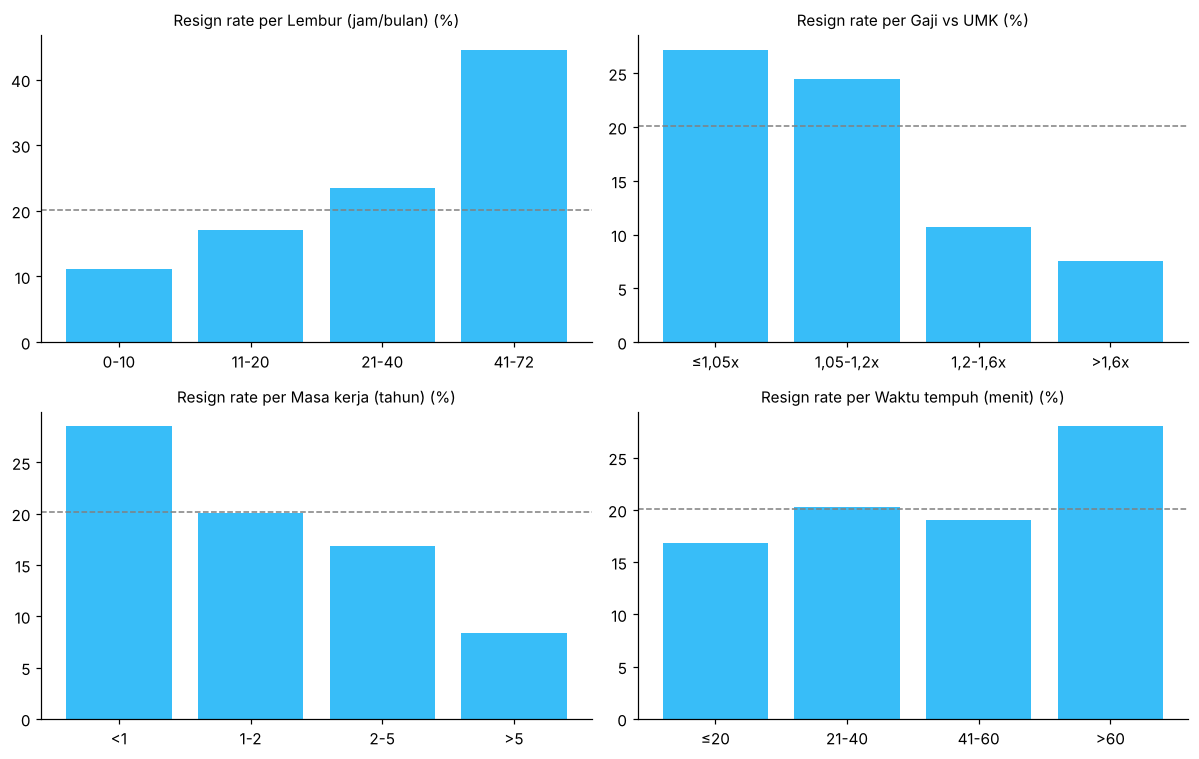

In [4]:
bins = {
    'Lembur (jam/bulan)': pd.cut(df.lembur_jam_per_bulan, [-1, 10, 20, 40, 72], labels=['0-10', '11-20', '21-40', '41-72']),
    'Gaji vs UMK': pd.cut(df.rasio_gaji_umk, [0, 1.05, 1.2, 1.6, 10], labels=['≤1,05x', '1,05-1,2x', '1,2-1,6x', '>1,6x']),
    'Masa kerja (tahun)': pd.cut(df.masa_kerja_tahun, [0, 1, 2, 5, 40], labels=['<1', '1-2', '2-5', '>5']),
    'Waktu tempuh (menit)': pd.cut(df.waktu_tempuh_menit, [0, 20, 40, 60, 200], labels=['≤20', '21-40', '41-60', '>60']),
}
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, (judul, b) in zip(ax.flat, bins.items()):
    r = df.groupby(b, observed=True).resign.mean() * 100
    a.bar(r.index.astype(str), r.values, color='#38bdf8'); a.axhline(df.resign.mean() * 100, ls='--', c='grey', lw=1)
    a.set_title(f'Resign rate per {judul} (%)', fontsize=10)
plt.tight_layout(); plt.show()

**Temuan EDA:**
- Frontliner **toko & gudang** resign ±2,5x lebih sering daripada kantor pusat; **driver, kasir, pramuniaga** paling rawan.
- **Kontrak (PKWT) & outsourcing** jauh di atas karyawan tetap.
- Risiko naik tajam pada **lembur > 40 jam/bulan** dan **gaji yang hanya sedikit di atas UMK**.
- **Tahun pertama** adalah masa paling rawan; perjalanan **> 1 jam** juga menaikkan risiko.

## 3. Rekayasa & pemilihan fitur yang adil
**Tidak dipakai:** gender, usia, status pernikahan, agama, suku — tidak ada di data dan tidak boleh dipakai untuk keputusan SDM. **Lokasi** juga tidak dipakai langsung (pengaruhnya sudah terwakili lewat rasio gaji-UMK dan waktu tempuh).

**Fitur rekayasa (domain Indonesia):**
- `log_rasio_gaji_umk` — gaji relatif terhadap UMK lokasi lebih bermakna daripada nominal Rupiah (Rp6 juta di Bekasi ≠ Rp6 juta di Bandung).
- `kontrak_habis_2bln` — PKWT yang kontraknya habis ≤ 2 bulan lagi.
- `masa_kerja_band` — tahun pertama vs 1–2 tahun vs lebih lama (hubungan tidak linear).

In [5]:
def fitur(d):
    out = d.copy()
    out['kontrak_habis_2bln'] = ((out.status_kerja == 'PKWT (kontrak)') & (out.sisa_kontrak_bulan <= 2)).astype(int)
    out['kinerja_terbaik'] = (out.nilai_kinerja == 5).astype(int)
    out['masa_kerja_band'] = pd.cut(out.masa_kerja_tahun, [0, 1, 2, 100], labels=['<1 th', '1-2 th', '>2 th']).astype(str)
    return out

NUM = ['lembur_jam_per_bulan', 'waktu_tempuh_menit', 'tahun_sejak_promosi', 'pelatihan_per_tahun',
       'kenaikan_gaji_terakhir_pct', 'kepuasan_kerja', 'hubungan_atasan', 'work_life_balance']
LOG = ['rasio_gaji_umk']
BIN = ['shift_malam', 'kontrak_habis_2bln', 'kinerja_terbaik']
CAT = ['status_kerja', 'jabatan', 'masa_kerja_band']
# kategori acuan (pertama) dipilih agar koefisien mudah dibaca: tetap, kasir, masa kerja > 2 th
CAT_ORDER = [['PKWTT (tetap)', 'PKWT (kontrak)', 'Outsourcing'],
             ['Kasir'] + sorted(j for j in df.jabatan.unique() if j != 'Kasir'),
             ['>2 th', '1-2 th', '<1 th']]
FEATURES = NUM + LOG + BIN + CAT

X = fitur(df)[FEATURES]; y = df.resign
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_tr.shape, f'resign {y_tr.mean():.1%} | Test:', X_te.shape, f'resign {y_te.mean():.1%}')

def preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM),
        ('log', Pipeline([('log', FunctionTransformer(np.log, feature_names_out='one-to-one')), ('sc', StandardScaler())]), LOG),
        ('bin', 'passthrough', BIN),
        ('cat', OneHotEncoder(categories=CAT_ORDER, handle_unknown='ignore', drop='first'), CAT)])

Train: (1920, 15) resign 20.1% | Test: (480, 15) resign 20.2%


## 4. Perbandingan model (5-fold cross-validation pada data latih)

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
kandidat = {
    'Logistic Regression': LogisticRegression(max_iter=3000, C=0.5),
    'Random Forest': RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced_subsample', random_state=RS, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=RS),
}
hasil, oof_all = [], {}
for nama, m in kandidat.items():
    oof = cross_val_predict(Pipeline([('prep', preprocessor()), ('model', m)]), X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
    oof_all[nama] = oof
    hasil.append({'Model': nama, 'ROC-AUC': roc_auc_score(y_tr, oof), 'PR-AUC': average_precision_score(y_tr, oof)})
cv_table = pd.DataFrame(hasil).sort_values('ROC-AUC', ascending=False).round(3)
cv_table

,Model,ROC-AUC,PR-AUC
0,Logistic Regression,0.779,0.500
1,Random Forest,0.752,0.438
2,Gradient Boosting,0.738,0.435


**Logistic Regression** dipilih: performanya setara/terbaik dan paling mudah dijelaskan ke HR (setiap faktor punya koefisien). Model dilatih tanpa `class_weight` agar output tetap berupa **peluang realistis**; ketidakseimbangan kelas ditangani lewat ambang keputusan.

## 5. Ambang keputusan (F1-score)
F2 (mengutamakan recall) menandai ~42% karyawan — terlalu banyak untuk ditindaklanjuti tim HR. F1 menyeimbangkan recall & precision sehingga daftar prioritas tetap realistis untuk program *stay interview*.

In [7]:
oof = oof_all['Logistic Regression']
grid = np.round(np.arange(0.10, 0.61, 0.01), 2)
f1 = [fbeta_score(y_tr, oof >= t, beta=1) for t in grid]
THRESHOLD = float(grid[int(np.argmax(f1))])
print(f'Ambang: {THRESHOLD:.2f} | CV recall {recall_score(y_tr, oof >= THRESHOLD):.1%} | CV precision {precision_score(y_tr, oof >= THRESHOLD):.1%} | ditandai {(oof >= THRESHOLD).mean():.0%} karyawan')

Ambang: 0.21 | CV recall 70.5% | CV precision 40.6% | ditandai 35% karyawan


## 6. Evaluasi akhir di data uji (sekali)

In [8]:
final = Pipeline([('prep', preprocessor()), ('model', LogisticRegression(max_iter=3000, C=0.5))]).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]; pred = (p_te >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
test_metrics = {'roc_auc': roc_auc_score(y_te, p_te), 'pr_auc': average_precision_score(y_te, p_te),
                'recall': recall_score(y_te, pred), 'precision': precision_score(y_te, pred),
                'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn), 'base_rate': float(y_te.mean())}
print(f"ROC-AUC {test_metrics['roc_auc']:.3f} | PR-AUC {test_metrics['pr_auc']:.3f} (acak = {y_te.mean():.3f})")
print(f"Recall {test_metrics['recall']:.1%} | Precision {test_metrics['precision']:.1%}")
pd.DataFrame([[tn, fp], [fn, tp]], index=['Aktual: bertahan', 'Aktual: resign'], columns=['Prediksi: aman', 'Prediksi: berisiko'])

ROC-AUC 0.763 | PR-AUC 0.515 (acak = 0.202)
Recall 67.0% | Precision 39.6%


,Prediksi: aman,Prediksi: berisiko
Aktual: bertahan,284,99
Aktual: resign,32,65


Fokus ke 10% karyawan berisiko tertinggi -> menangkap 31% yang resign
Fokus ke 20% karyawan berisiko tertinggi -> menangkap 43% yang resign
Fokus ke 30% karyawan berisiko tertinggi -> menangkap 61% yang resign
Fokus ke 40% karyawan berisiko tertinggi -> menangkap 71% yang resign
Fokus ke 50% karyawan berisiko tertinggi -> menangkap 77% yang resign


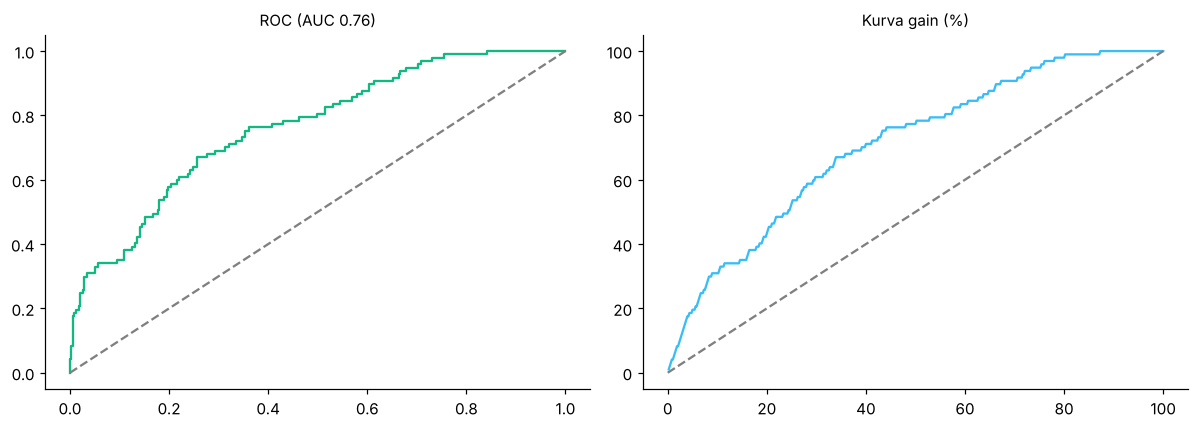

In [9]:
order = np.argsort(-p_te); cum = np.cumsum(y_te.values[order]) / y_te.sum(); pct = np.arange(1, len(order) + 1) / len(order)
gain = {int(k): float(cum[int(np.ceil(k / 100 * len(order))) - 1]) for k in [10, 20, 30, 40, 50]}
for k, v in gain.items(): print(f'Fokus ke {k:>2}% karyawan berisiko tertinggi -> menangkap {v:.0%} yang resign')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr, c='#10b981'); ax[0].plot([0, 1], [0, 1], ls='--', c='grey'); ax[0].set_title(f"ROC (AUC {test_metrics['roc_auc']:.2f})", fontsize=10)
ax[1].plot(pct * 100, cum * 100, c='#38bdf8'); ax[1].plot([0, 100], [0, 100], ls='--', c='grey'); ax[1].set_title('Kurva gain (%)', fontsize=10)
plt.tight_layout(); plt.show()

## 7. Faktor pendorong resign (koefisien & odds ratio)

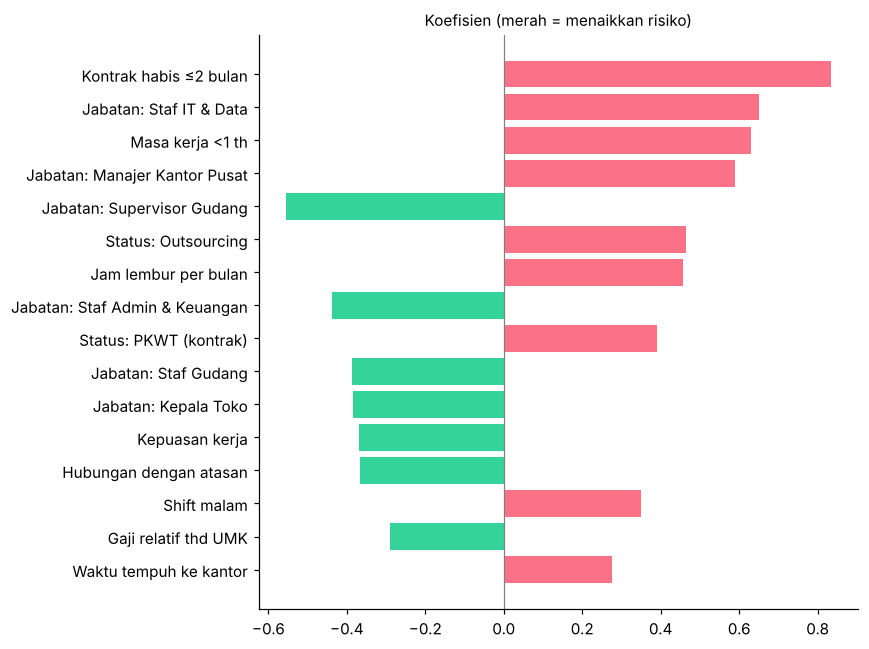

,faktor,koef,odds_ratio
0,Kontrak habis ≤2 bulan,0.83,2.30
1,Jabatan: Staf IT & Data,0.65,1.92
2,Masa kerja <1 th,0.63,1.88
3,Jabatan: Manajer Kantor Pusat,0.59,1.80
4,Jabatan: Supervisor Gudang,-0.56,0.57
5,Status: Outsourcing,0.47,1.59
6,Jam lembur per bulan,0.46,1.58
7,Jabatan: Staf Admin & Keuangan,-0.44,0.65
8,Status: PKWT (kontrak),0.39,1.48
9,Jabatan: Staf Gudang,-0.39,0.68


In [10]:
prep, lr = final.named_steps['prep'], final.named_steps['model']
names = prep.get_feature_names_out(); coef = pd.Series(lr.coef_[0], index=names)
LABEL = {'lembur_jam_per_bulan': 'Jam lembur per bulan', 'waktu_tempuh_menit': 'Waktu tempuh ke kantor',
         'tahun_sejak_promosi': 'Lama sejak promosi', 'pelatihan_per_tahun': 'Jumlah pelatihan',
         'kenaikan_gaji_terakhir_pct': 'Kenaikan gaji terakhir', 'kepuasan_kerja': 'Kepuasan kerja',
         'hubungan_atasan': 'Hubungan dengan atasan', 'work_life_balance': 'Work-life balance',
         'rasio_gaji_umk': 'Gaji relatif thd UMK', 'shift_malam': 'Shift malam', 'kontrak_habis_2bln': 'Kontrak habis ≤2 bulan', 'kinerja_terbaik': 'Kinerja terbaik (nilai 5)'}
def label(n):
    raw = n.split('__', 1)[1]
    for pre, lab in [('status_kerja_', 'Status: '), ('jabatan_', 'Jabatan: '), ('masa_kerja_band_', 'Masa kerja ')]:
        if raw.startswith(pre): return lab + raw[len(pre):]
    return LABEL.get(raw, raw)
drivers = pd.DataFrame({'faktor': [label(n) for n in names], 'koef': coef.values, 'odds_ratio': np.exp(coef.values)})
drivers = drivers.reindex(drivers.koef.abs().sort_values(ascending=False).index).reset_index(drop=True)
top = drivers.head(16).iloc[::-1]
plt.figure(figsize=(8, 6)); plt.barh(top.faktor, top.koef, color=['#fb7185' if k > 0 else '#34d399' for k in top.koef])
plt.axvline(0, c='grey', lw=.8); plt.title('Koefisien (merah = menaikkan risiko)', fontsize=10); plt.tight_layout(); plt.show()
drivers.head(16).round(2)

**Rekomendasi untuk HR PT NusaMart:**
1. **Kendalikan lembur frontliner** — jam lembur adalah pendorong terbesar yang bisa langsung dikendalikan (rotasi shift, tambah tenaga saat peak season/Lebaran).
2. **Review gaji yang "mepet UMK"** — kenaikan kecil di atas UMK berdampak besar pada risiko.
3. **Program onboarding tahun pertama** dan **keputusan perpanjangan PKWT lebih awal** (jangan menunggu kontrak habis).
4. **Kualitas atasan** (kepala toko/supervisor) dan **jalur promosi** yang jelas untuk staf.

**Catatan etis:** skor dipakai untuk memprioritaskan percakapan retensi — bukan dasar menolak perpanjangan kontrak, disiplin, atau PHK.

## 8. Ekspor model untuk simulator web

In [11]:
imp = prep.named_transformers_['num'].named_steps['imp']; sc = prep.named_transformers_['num'].named_steps['sc']
sl = prep.named_transformers_['log'].named_steps['sc']; ohe = prep.named_transformers_['cat']
model_json = {
    'intercept': float(lr.intercept_[0]), 'threshold': THRESHOLD, 'base_rate': float(y.mean()),
    'num': [{'name': n, 'median': float(md_), 'mean': float(m), 'scale': float(s), 'coef': float(coef['num__' + n])}
            for n, md_, m, s in zip(NUM, imp.statistics_, sc.mean_, sc.scale_)],
    'log': [{'name': n, 'mean': float(m), 'scale': float(s), 'coef': float(coef['log__' + n])} for n, m, s in zip(LOG, sl.mean_, sl.scale_)],
    'bin': [{'name': n, 'coef': float(coef['bin__' + n]), 'mean': float(X_tr[n].mean())} for n in BIN],
    'cat': [{'name': n, 'base': str(cats[0]), 'coef': {str(c): float(coef[f'cat__{n}_{c}']) for c in cats[1:]},
             'mean': {str(c): float((X_tr[n].astype(str) == str(c)).mean()) for c in cats[1:]}} for n, cats in zip(CAT, ohe.categories_)],
}
d2 = fitur(df)
def rate_list(s, order=None):
    g = d2.groupby(s, observed=True).resign.agg(['size', 'mean'])
    if order: g = g.reindex(order)
    return [{'k': str(k), 'n': int(n), 'r': float(r)} for k, (n, r) in g.iterrows()]
fpr, tpr, _ = roc_curve(y_te, p_te); idx = np.unique(np.linspace(0, len(fpr) - 1, 60).astype(int))
report = {
    'n': len(df), 'n_resign': int(y.sum()), 'n_train': len(X_tr), 'n_test': len(X_te),
    'cv': cv_table.to_dict('records'), 'test': test_metrics, 'gain': gain,
    'gain_curve': [[round(float(a) * 100, 1), round(float(b) * 100, 1)] for a, b in zip(pct[::3], cum[::3])],
    'roc': [[round(float(fpr[i]), 3), round(float(tpr[i]), 3)] for i in idx],
    'drivers': drivers.head(16).round(3).to_dict('records'),
    'eda': {
        'unit': rate_list('unit'), 'jabatan': rate_list('jabatan'), 'status_kerja': rate_list('status_kerja'),
        'lembur': rate_list(bins['Lembur (jam/bulan)']), 'gaji_umk': rate_list(bins['Gaji vs UMK']),
        'masa_kerja': rate_list(bins['Masa kerja (tahun)']), 'tempuh': rate_list(bins['Waktu tempuh (menit)']),
    },
    'umk': df.groupby('lokasi').umk_lokasi.first().astype(int).to_dict(),
    'jabatan_meta': df.groupby('jabatan').agg(unit=('unit', 'first'), gaji_median=('gaji_pokok', 'median')).reset_index().to_dict('records'),
}
json.dump({'model': model_json, 'report': report}, open('attrition_model.json', 'w'), ensure_ascii=False, indent=1)

def score(r):
    z = model_json['intercept']
    for f in model_json['num']:
        v = r[f['name']]; v = f['median'] if pd.isna(v) else v
        z += f['coef'] * (v - f['mean']) / f['scale']
    for f in model_json['log']: z += f['coef'] * (np.log(r[f['name']]) - f['mean']) / f['scale']
    for f in model_json['bin']: z += f['coef'] * r[f['name']]
    for f in model_json['cat']: z += f['coef'].get(str(r[f['name']]), 0.0)
    return 1 / (1 + np.exp(-z))
print('Selisih maks JSON vs sklearn:', float(np.abs(np.array([score(r) for _, r in X_te.iterrows()]) - p_te).max()))

Selisih maks JSON vs sklearn: 2.220446049250313e-16


## 9. Kesimpulan & batasan
- Logistic Regression dengan faktor kerja khas Indonesia (rasio gaji-UMK, status PKWT/outsourcing, lembur, shift malam, waktu tempuh) memberi skor risiko yang **bisa dijelaskan** dan memprioritaskan karyawan secara efisien (lihat kurva gain).
- **Batasan:** data sintetis — angka resign dan efek tiap faktor berasal dari asumsi kalibrasi, sehingga model "menemukan kembali" pola yang dirancang. Untuk dipakai sungguhan, pipeline yang sama harus dilatih ulang dengan data HRIS perusahaan, divalidasi, dan dipantau berkala.